In [9]:
import cvxpy as cp
import numpy as np

# Problem data.
m = 30
n = 20
np.random.seed(1)
A = np.random.standard_normal((m, n))
b = np.random.standard_normal((m))

# Construct the problem.
x = cp.Variable(n)
objective = cp.Minimize(cp.sum_squares(A @ x - b))
constraints = [0 <= x, x <= 1]
prob = cp.Problem(objective, constraints)

# The optimal objective value is returned by `prob.solve()`.
result = prob.solve()
print(f"Minimum value of function: {result}")
print(f"Optimal value of variables: \n\t x =  {x.value}")
print(f"Optimal Lagrange multiplier for constraints: \n\t mu = {constraints[0].dual_value}")


Minimum value of function: 19.83126370644502
Optimal value of variables: 
	 x =  [-1.77954394e-19  2.85112420e-02  2.80055377e-19  3.10748884e-20
 -2.72854468e-19  1.49285011e-01 -9.99853941e-20  8.50301053e-20
  2.46718649e-01  5.78224144e-01 -4.05134357e-19  1.01242860e-03
 -9.44858899e-20  2.26767464e-01 -1.57215873e-19 -8.89669513e-20
 -1.21382480e-19 -1.52713017e-19  1.11243463e-19 -3.48540577e-19]
Optimal Lagrange multiplier for constraints: 
	 mu = [ 2.50938945  0.          2.78354615  1.79425782 13.08579183  0.
  0.73716363  3.35344995  0.          0.          8.93825054  0.
  7.02955161  0.          4.71068649  3.18873635  2.06090107 10.08166738
  3.0481157   8.53268239]


## Exercise 4.3 

Rather than building the proof, let's see if we can use cvxpy to calculate $x^\star$
and see if it is $(1, \frac{1}{2}, -1)$.

Turns out that this isn't a convex problem ... maybe instructive anyway?

In [5]:
import cvxpy as cp
import numpy as np

# Problem data.
p = np.array(((13, 12, -2),
              (12, 17,  6),
              (-2,  6, 12)))
q = np.array((-22.0, -14.5, 13.0))
r = 1

# Construct the problem.
x = cp.Variable(3)
objective = cp.Minimize((1/2) * x.T @ p @ x + q.T @ x + r)
constraints = [-1 <= x, x <= 1]
prob = cp.Problem(objective, constraints)

# The optimal objective value is returned by `prob.solve()`.
result = prob.solve()
# The optimal value for x is stored in `x.value`.
print(x.value)

DCPError: Problem does not follow DCP rules. Specifically:
The objective is not DCP. Its following subexpressions are not:
Promote(0.5, (3,)) * var85 @ [[13.00 12.00 -2.00]
 [12.00 17.00 6.00]
 [-2.00 6.00 12.00]] @ var85

# Can we code up Figure 4.12?

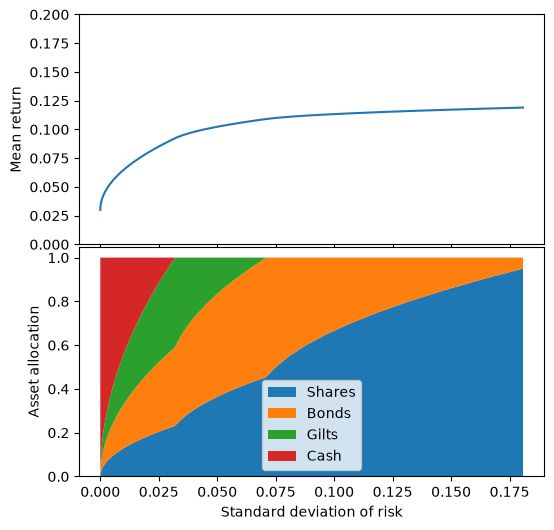

In [39]:
import cvxpy as cp
import numpy as np
import matplotlib.pyplot as plt

# Problem data (table on page 168).
n = 4
labels = ["Shares", "Bonds", "Gilts", "Cash"]
sigma = np.zeros((4,4))
sigma[0,0] = 0.2
sigma[1,1] = 0.1
sigma[2,2] = 0.05
sigma[3,3] = 0.0 # variance
p = np.array((0.12, 0.10, 0.07, 0.03)) # Prices
x = cp.Variable(n) # Asset allocations (solved for)

# problem parameters ()
r_min = cp.Parameter(nonneg=True) # Minimum acceptable return


# Construct the problem.

objective = cp.Minimize(x.T @ sigma @ x)
mean_return = p.T @ x
constraints = [mean_return >= r_min,
               cp.sum(x) == 1,
               x >= 0]
prob = cp.Problem(objective, constraints)

# results for plotting
mean_returns = []
allocations = []
risks = []

for target in np.arange(0.02, 0.12, 0.001):
    r_min.value = target
    # The optimal objective value is returned by `prob.solve()`.
    result = prob.solve()
    # The optimal value for x is stored in `x.value`.
    #print(f"For target minimum return of {target}")
    #print(f"calculated risk is: {objective.value}")
    risks.append(objective.value)
    #print(f"mean return is: {mean_return.value}")
    mean_returns.append(mean_return.value)
    #print(f"asset allocation: {x.value}")
    allocations.append(x.value)

fig, axs = plt.subplots(nrows=2, sharex=True, figsize=(6, 6))
fig.subplots_adjust(hspace=0.01)
axs[0].plot(risks, mean_returns)
axs[0].set_ylim(0.0, 0.20)
axs[0].set_ylabel("Mean return")
a = np.array(allocations)
axs[1].stackplot(risks, a.T, labels=labels)
axs[1].legend()
axs[1].set_xlabel("Standard deviation of risk")
axs[1].set_ylabel("Asset allocation")

plt.show()

